# Figure 1

This notebook generates pipeline descriptions for HTDS and Swiper

In [1]:
from diagrams import Diagram, Cluster
from diagrams.generic.blank import Blank
from diagrams.generic.compute import Rack
from diagrams.generic.device import Mobile
from diagrams.generic.place import Datacenter
from diagrams import Diagram, Edge
from diagrams.custom import Custom

image_paths = {
    "cleavage": "CRISPR-CAS9-pink.png",
    "gel": "electrophoresis-gel.png",
    "screening": "DNA_sequencer.png", 
    "pam": "AlkaCas.5.png"
}

# Custom node creation function
def create_step(label, image, width="1.5", height="2"):
    #return Blank(label, width=width, height=height)
    return Custom(label, image, width=width, height=height)

with Diagram("Traditional PAM Recovery Workflow", 
             show=False, 
             filename="cleavage_assay_workflow", 
             direction="LR",
             outformat="png", 
             graph_attr={
                "labelloc": "t", "labeljust": "c", "fontsize": "14",
                "ratio":"compress", 
                "ranksep": "0.5",      # Reduced vertical spacing between ranks
                "nodesep": "0.1",      # Reduced horizontal spacing between nodes
                "margin": "0",       # Reduced margin around the graph,
                "pad": "0.1",          # Minimal padding,
                "dpi": "300",
                "concentrate": "true", 
                "labeldistance": "0",      # Remove space after label
                "labelfloat": "true",      # Allow label to be closer
             }
            ):

    # Create all workflow steps
    cleavage_assay = create_step("Cleavage Assay", image_paths["cleavage"])
    gel_electrophoresis = create_step("Gel Electrophoresis", image_paths["gel"])
    screening = create_step("NGS", image_paths["screening"])
    pam_analysis = create_step("PAM Analysis", image_paths["pam"])
    
    # Connect the workflow with arrows
    cleavage_assay >> gel_electrophoresis >> screening >> pam_analysis

print("Diagram generated successfully as 'cleasure_assay_workflow.png'")

Diagram generated successfully as 'cleasure_assay_workflow.png'


In [2]:
from diagrams import Cluster, Diagram
from diagrams.aws.compute import ECS, EKS, Lambda
from diagrams.aws.database import Redshift
from diagrams.aws.integration import SQS
from diagrams.aws.storage import S3

IMAGE_PATHS = {
    "dna_synthesis": "plasmid-l-insert-dna.png",
    "swiper": "swiper.png",
    "active_learning": "ai.png",
    "cleavage_assay": "CRISPR-CAS9-pink.png",
    "gel_electrophoresis": "electrophoresis-gel.png",
    "screening": "DNA_sequencer.png", 
    "human_labeling": "Scientist_female.png",
    "pam_candidates": "Document.png",
    "pam_estimation": "AlkaCas.5.png"
}


WIDTH = "3"
HEIGHT = "4"


with Diagram(
    "PAM Discovery with Active Learning", show=False,
    filename="pam_discovery_with_active_learning",
    direction="TB",
    graph_attr={
                "labelloc": "t", "labeljust": "c", "fontsize": "14",
                "ratio":"compress", 
                "ranksep": "0.2",      # Reduced vertical spacing between ranks
                "nodesep": "0.1",      # Reduced horizontal spacing between nodes
                "margin": "0",       # Reduced margin around the graph,
                "pad": "0",          # Minimal padding,
                "dpi": "300",
                "concentrate": "true", 
                "labeldistance": "0",      # Remove space after label
                "labelfloat": "true",      # Allow label to be closer
                "fontsize": "30"
             }
):

    with Cluster("Active Learning Loop"):
        with Cluster("Experimental Setup", graph_attr={"bgcolor": "#E4D2C6", "color": "#E4D2C6", "style": "filled"}) as ES:
            experimental = [
                        Custom("Gel Electrophoresis", IMAGE_PATHS["gel_electrophoresis"], width=WIDTH, height=HEIGHT),
                        Custom("Cleavage Assay", IMAGE_PATHS["cleavage_assay"], width=WIDTH, height=HEIGHT),
                        Custom("DNA Synthesis", IMAGE_PATHS["dna_synthesis"], width=WIDTH, height=HEIGHT),
                        Custom("PAM Candidates", IMAGE_PATHS["pam_candidates"], width=WIDTH, height=HEIGHT),
            ]

        human = Custom("Human Labeling by Experimentation", IMAGE_PATHS["human_labeling"], width=WIDTH, height=HEIGHT)

        with Cluster("SWIPER pipeline", graph_attr={"bgcolor": "#E4D2C6", "color": "#E4D2C6", "style": "filled"}) as SP:
            analytics = [
                Custom("Current PAM Prediction", IMAGE_PATHS["pam_estimation"], width=WIDTH, height=HEIGHT),
                Custom("New PAM Candidates to Test", IMAGE_PATHS["pam_candidates"], width=WIDTH, height=HEIGHT),
                Custom("Active Learning", IMAGE_PATHS["active_learning"], width=WIDTH, height=HEIGHT),
            ]

    human >> experimental[-1]
    experimental[0] >> human
    human >> analytics[-1]
    analytics[0] >> human

In [3]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from PIL import Image
import numpy as np

In [4]:
img_a = np.array(Image.open('cleavage_assay_workflow.png').convert('RGB'))  # Replace with your image paths
img_b = np.array(Image.open('pam_discovery_with_active_learning.png').convert('RGB'))

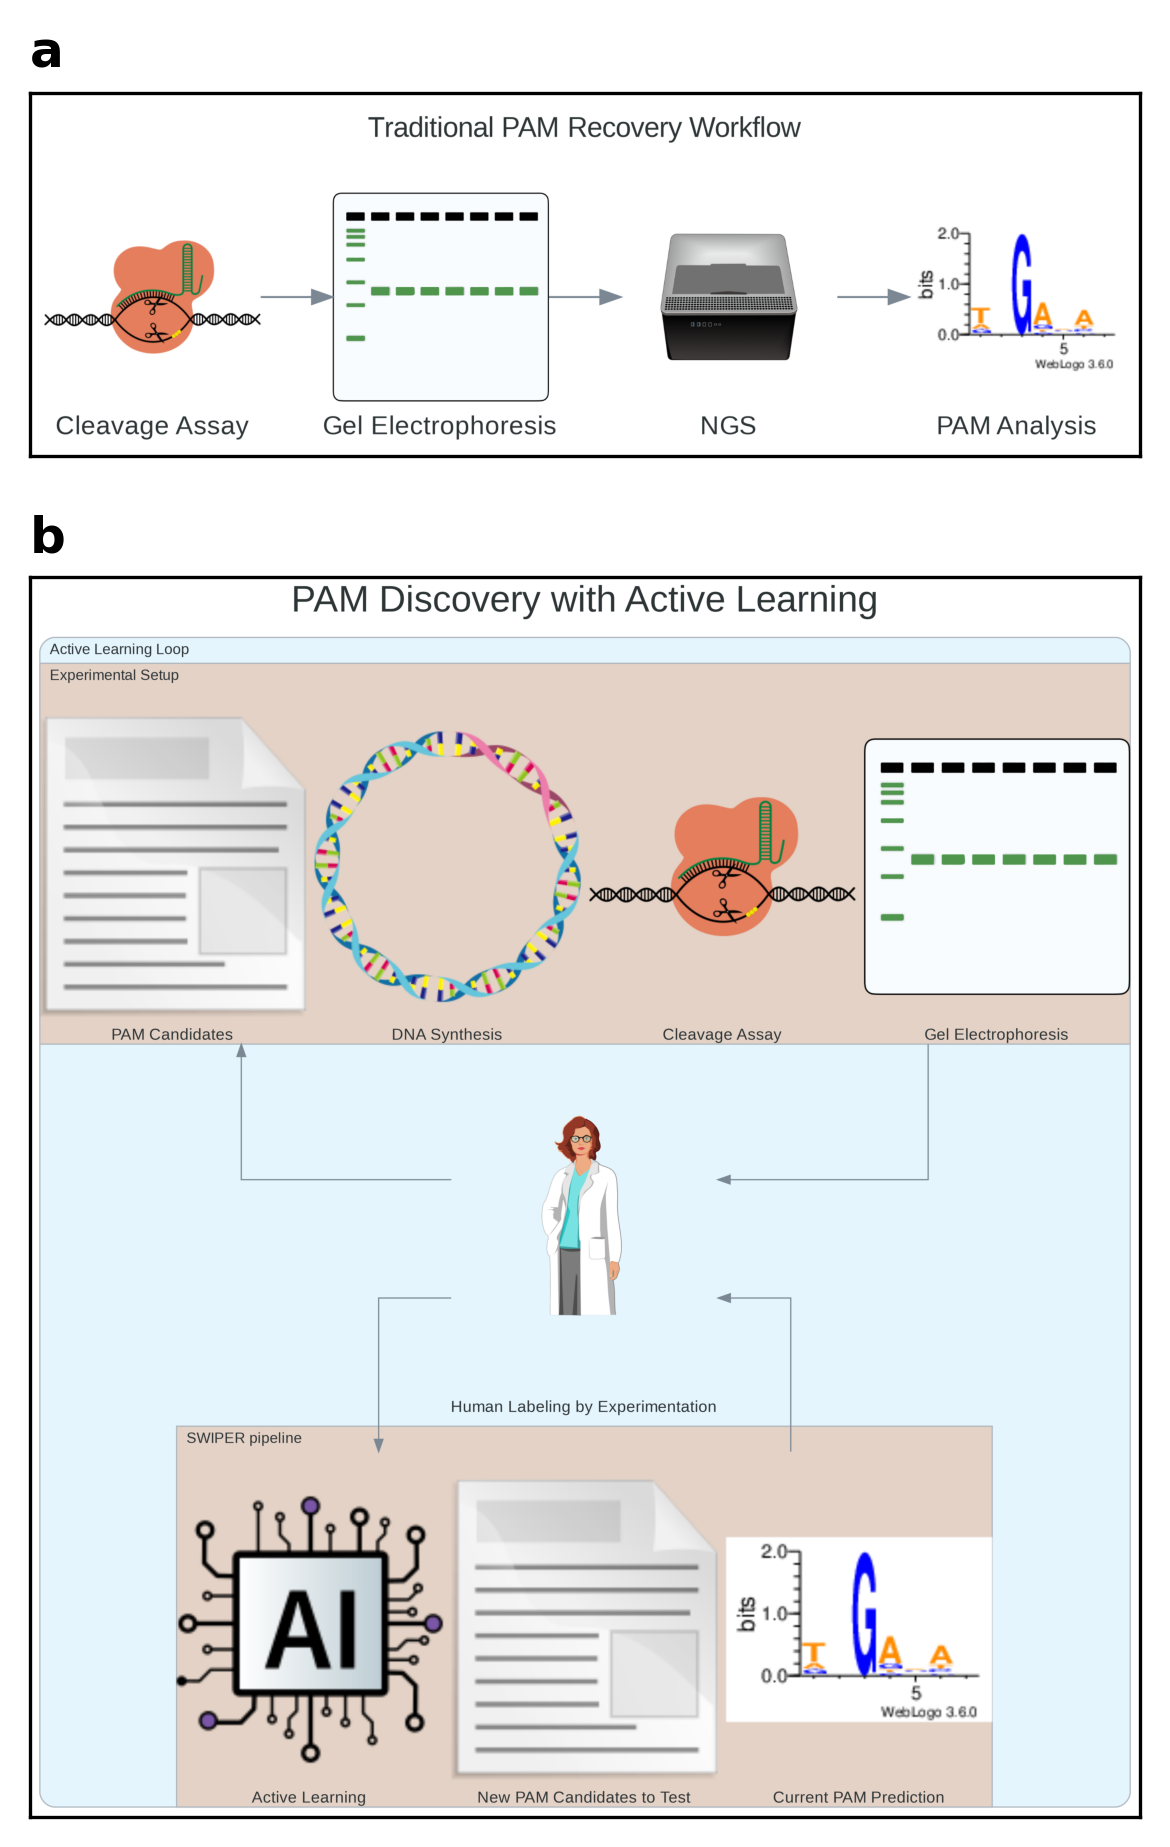

In [5]:
plt.rcParams["figure.figsize"] = 4, 10
plt.rcParams["figure.dpi"] = 300

pattern = [
    ["A", "A"],
    ["B", "B"],
    ["B", "B"],
    ["B", "B"],
]

# Create figure and mosaic layout
fig, axd = plt.subplot_mosaic(
    pattern,
    figsize=(4, 6.5),
    gridspec_kw={
        "wspace": 0,
        "hspace": 0,
    },
    layout='tight'
)

fig.subplots_adjust(wspace=0, hspace=0)



axd["A"].imshow(img_a)
axd["A"].set_xticks([])
axd["A"].set_yticks([])
axd["A"].set_title("a", loc='left', weight="bold")
axd["B"].imshow(img_b)
axd["B"].set_xticks([])
axd["B"].set_yticks([])
axd["B"].set_title("b", loc='left', weight="bold")

fig.savefig("../Figure1.png")